<a href="https://colab.research.google.com/github/nicolaselias7/Atividade-I---CN/blob/main/Atv2_CN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cálculo Numérico — Atividade Prática II
## Estabilidade e overflow em uma simulação de difusão de velocidade

**Disciplina:** Cálculo Numérico — Prof. Raquel J. Lobosco
**Instituição:** UNIFESP

**Dupla:**
- Nicolas Elias dos Santos — RA: 178196
- Gabriel Andreatta Padilha — RA: 176297

---


## Objetivos

Investigar a relação entre estabilidade numérica, passo de tempo e ocorrência de *overflow* em uma simulação simplificada de dinâmica dos fluidos computacional (escoamento de Couette entre placas paralelas).

Ao final da atividade, seremos capazes de:

- explicar o overflow em números de ponto flutuante;
- distinguir instabilidade numérica de overflow;
- calcular o limite de estabilidade do método utilizado;
- detectar falhas numéricas em Python;
- avaliar os efeitos do tipo numérico.


## Configuração inicial

Importação das bibliotecas utilizadas ao longo do notebook.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

%matplotlib inline

print("Maior float32:", np.finfo(np.float32).max)
print("Maior float64:", np.finfo(np.float64).max)

Maior float32: 3.4028235e+38
Maior float64: 1.7976931348623157e+308


## Dados da simulação

| Parâmetro | Valor |
|---|---|
| Distância entre placas, $H$ | 0,01 m |
| Viscosidade cinemática, $\nu$ | $10^{-4}$ m²/s |
| Número de pontos (incluindo paredes) | 21 |
| Velocidade da placa móvel, $U$ | 1 m/s |
| Velocidade da placa fixa | 0 m/s |

O esquema utilizado é Euler explícito no tempo e diferenças finitas centrais no espaço:

$$u_i^{n+1} = u_i^n + r\left(u_{i+1}^n - 2u_i^n + u_{i-1}^n\right), \qquad r = \frac{\nu \Delta t}{\Delta y^2}$$

A condição de estabilidade desse esquema de difusão 1D é $r \le \dfrac{1}{2}$, ou seja $\Delta t \le \dfrac{\Delta y^2}{2\nu}$.


## 1. Verificação da estabilidade

Cálculo de $\Delta y$, $\Delta t_{max}$ e $r$ para os casos A ($\Delta t = 0{,}001$ s) e B ($\Delta t = 0{,}002$ s), classificando cada um como estável ou instável **antes** de executar a simulação.

In [ ]:
H = 0.01
nu = 1e-4
pontos = 21

dy = H / (pontos - 1)
dt_max = dy**2 / (2 * nu)

print(f"dy      = {dy} m")
print(f"dt_max  = {dt_max} s")
print()

casos = {"Caso A": 0.001, "Caso B": 0.002}
for nome, dt in casos.items():
    r = nu * dt / dy**2
    status = "ESTAVEL (r <= 1/2)" if r <= 0.5 else "INSTAVEL (r > 1/2)"
    print(f"{nome}: dt = {dt} s -> r = {r:.4f} -> {status}")

dy      = 0.0005 m
dt_max  = 0.0012499999999999998 s

Caso A: dt = 0.001 s -> r = 0.4000 -> ESTAVEL (r <= 1/2)
Caso B: dt = 0.002 s -> r = 0.8000 -> INSTAVEL (r > 1/2)


**Resultado esperado:** $\Delta y = 0{,}0005$ m e $\Delta t_{max} = 0{,}00125$ s.

- **Caso A** ($\Delta t = 0{,}001$ s): $r = 0{,}4 \le 1/2$ → **estável**.
- **Caso B** ($\Delta t = 0{,}002$ s): $r = 0{,}8 > 1/2$ → **instável**.

Como $\Delta t = 0{,}002$ s $> \Delta t_{max} = 0{,}00125$ s, já era esperado que o Caso B apresentasse crescimento numérico não físico.

## 2. Detecção de overflow

Função `simular`, fornecida no enunciado, que resolve a equação de difusão e interrompe a simulação assim que detecta overflow ou operação inválida (`np.errstate`).

In [ ]:
def simular(dt, tipo=np.float32, passos=2000, pontos=21):
    """Simula difusao de velocidade e detecta falhas."""
    H = 0.01
    nu = 1e-4
    y = np.linspace(0, H, pontos)
    dy = H / (pontos - 1)

    # Coeficientes no tipo numerico escolhido.
    r = tipo(nu * dt / dy**2)
    dois = tipo(2)

    # Fluido parado e placa em y=0 em movimento.
    u = np.zeros(pontos, dtype=tipo)
    u[0] = tipo(1)

    tempos = [0.0]
    maximos = [float(np.max(np.abs(u)))]
    falha = None

    # Transforma avisos numericos em excecoes.
    with np.errstate(over="raise", invalid="raise"):
        for passo in range(1, passos + 1):
            try:
                novo = u.copy()
                # Atualiza o interior e preserva as paredes.
                novo[1:-1] = (
                    u[1:-1]
                    + r * (u[2:] - dois * u[1:-1] + u[:-2])
                )
            except FloatingPointError as erro:
                falha = passo
                print(
                    f"dt={dt}, {tipo.__name__}: "
                    f"falha no passo {passo}, "
                    f"t={passo * dt:.4f} s - {erro}"
                )
                break
            u = novo
            tempos.append(passo * dt)
            maximos.append(float(np.max(np.abs(u))))

    if falha is None:
        print(
            f"dt={dt}, {tipo.__name__}: "
            f"{passos} passos sem overflow."
        )

    return {
        "y": y,
        "u": u,
        "tempos": tempos,
        "maximos": maximos,
        "r": float(r),
        "falha": falha,
    }

In [ ]:
resultados = {}
for tipo in (np.float32, np.float64):
    for dt in (0.001, 0.002):
        nome = f"{tipo.__name__}, dt={dt}"
        resultados[nome] = simular(dt, tipo)

dt=0.001, float32: 2000 passos sem overflow.
dt=0.002, float32: falha no passo 121, t=0.2420 s - overflow encountered in subtract
dt=0.001, float64: 2000 passos sem overflow.
dt=0.002, float64: falha no passo 917, t=1.8340 s - overflow encountered in add


### Tabela dos testes

In [ ]:
linhas = []
for nome, res in resultados.items():
    tipo_nome, dt_str = nome.split(", ")
    dt_val = float(dt_str.replace("dt=", ""))
    linhas.append({
        "Tipo numerico": tipo_nome,
        "dt (s)": dt_val,
        "r": round(res["r"], 4),
        "Overflow": "Sim" if res["falha"] is not None else "Nao",
        "Passo da falha": res["falha"] if res["falha"] is not None else "-",
        "Tempo da falha (s)": round(res["falha"] * dt_val, 4) if res["falha"] is not None else "-",
    })

tabela = pd.DataFrame(linhas)
tabela

,Tipo numerico,dt (s),r,Overflow,Passo da falha,Tempo da falha (s)
0,float32,0.001,0.4,Nao,-,-
1,float32,0.002,0.8,Sim,121,0.242
2,float64,0.001,0.4,Nao,-,-
3,float64,0.002,0.8,Sim,917,1.834


### Gráfico do crescimento da velocidade

/usr/local/lib/python3.12/dist-packages/matplotlib/scale.py:270: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


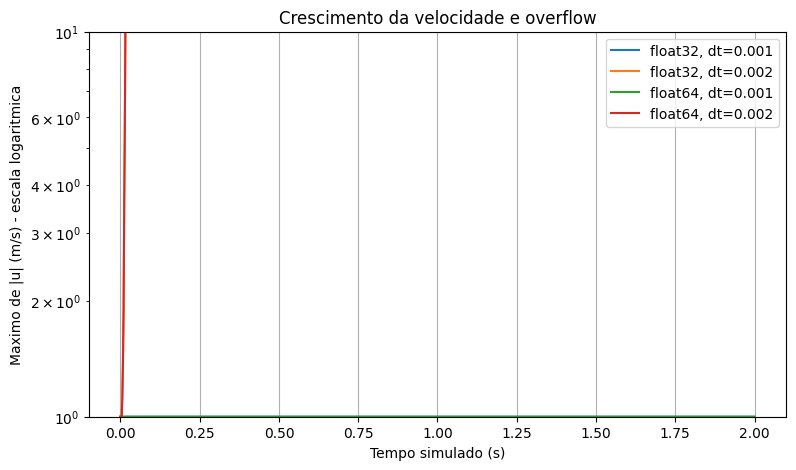

In [ ]:
plt.figure(figsize=(9, 5))
for nome, resultado in resultados.items():
    plt.semilogy(
        resultado["tempos"],
        resultado["maximos"],
        label=nome
    )
plt.xlabel("Tempo simulado (s)")
plt.ylabel("Maximo de |u| (m/s) - escala logaritmica")
plt.title("Crescimento da velocidade e overflow")
plt.grid(True)
plt.legend()
plt.show()

## 3. Interpretação física

No **Caso A** ($r = 0{,}4$), a velocidade máxima permanece limitada em $U = 1$ m/s durante toda a simulação: os coeficientes da atualização, $r$, $(1-2r)$ e $r$, são todos não negativos e somam 1, de modo que cada novo valor de $u_i$ é uma **média ponderada** dos valores vizinhos no passo anterior. Isso reproduz corretamente o efeito suavizante (dissipativo) da difusão.

No **Caso B** ($r = 0{,}8$), o coeficiente central $(1-2r) = 1 - 1{,}6 = -0{,}6$ torna-se **negativo**. A atualização deixa de ser uma média ponderada e passa a amplificar diferenças entre pontos vizinhos a cada passo, gerando oscilações que crescem exponencialmente. É por isso que o gráfico em escala logarítmica mostra o máximo de $|u|$ subindo em linha praticamente reta (crescimento exponencial) até ultrapassar o maior valor representável e ocorrer o overflow.

Fisicamente, a velocidade do escoamento deve satisfazer $0 \le u(y,t) \le U = 1$ m/s — o fluido nunca pode se mover mais rápido que a placa que o arrasta. Assim, valores de $|u|$ muito superiores a 1 m/s já denunciam uma solução **numericamente inválida**, mesmo antes de o programa registrar o overflow propriamente dito. O overflow é apenas a consequência tardia (e visível) de uma instabilidade que já havia corrompido o resultado bem antes.

## 4. Capacidade de representação (float32 vs float64)

Observando a tabela e o gráfico do Caso B (instável, $r=0{,}8$):

- em **float32**, a falha ocorre por volta do passo **121** ($t \approx 0{,}242$ s);
- em **float64**, a falha ocorre muito mais tarde, por volta do passo **917** ($t \approx 1{,}834$ s).

Isso ocorre porque o maior valor finito representável em `float64` ($\approx 1{,}8\times10^{308}$) é enormemente maior que em `float32` ($\approx 3{,}4\times10^{38}$), além de o `float64` ter mais bits de mantissa (52 contra 23), o que também retarda o acúmulo de erros de arredondamento. Como o crescimento no regime instável é aproximadamente exponencial, a cada passo o valor é multiplicado por um fator maior que 1; para atingir um limite ~270 ordens de grandeza mais alto (float64 vs float32), são necessários muitos passos adicionais.

**Importante:** a mudança de tipo numérico **não elimina** a instabilidade — ela apenas **adia o instante em que o overflow se torna visível**. O Caso B continua fisicamente incorreto em float64 muito antes do passo 917 (a velocidade já ultrapassa 1 m/s nos primeiros passos). Já o Caso A ($r=0{,}4$), que satisfaz a condição de estabilidade, permanece bem comportado em **ambos** os tipos numéricos pelos 2000 passos completos — a estabilidade depende de $r$, não do tipo numérico escolhido.

## 5. Refinamento da malha (41 pontos)

Repetindo o cálculo do limite de estabilidade com `pontos=41`.

In [ ]:
pontos_novo = 41
dy_novo = H / (pontos_novo - 1)
dt_max_novo = dy_novo**2 / (2 * nu)

print(f"Malha com {pontos_novo} pontos")
print(f"dy      = {dy_novo} m  (antes era {dy} m)")
print(f"dt_max  = {dt_max_novo} s  (antes era {dt_max} s)")

Malha com 41 pontos
dy      = 0.00025 m  (antes era 0.0005 m)
dt_max  = 0.00031249999999999995 s  (antes era 0.0012499999999999998 s)


Ao dobrar o número de pontos, $\Delta y$ cai pela metade e, como $\Delta t_{max} \propto \Delta y^2$, o novo limite de estabilidade cai para **1/4** do valor anterior. Ou seja, o mesmo $\Delta t = 0{,}001$ s que era estável na malha de 21 pontos ($r=0{,}4$) passa a ser fortemente instável na malha de 41 pontos.

Testando primeiro com $\Delta t = 0{,}001$ s (mantido) e depois com um passo de tempo abaixo do novo limite ($\Delta t = 0{,}0001$ s, $r=0{,}16$):

In [ ]:
print("Teste 1: mantendo dt = 0.001 s na malha refinada")
res_instavel_41 = simular(0.001, np.float64, passos=2000, pontos=41)

print()
print("Teste 2: reduzindo para dt = 0.0001 s (abaixo do novo limite)")
res_estavel_41 = simular(0.0001, np.float64, passos=20000, pontos=41)

Teste 1: mantendo dt = 0.001 s na malha refinada
dt=0.001, float64: falha no passo 426, t=0.4260 s - overflow encountered in subtract

Teste 2: reduzindo para dt = 0.0001 s (abaixo do novo limite)
dt=0.0001, float64: 20000 passos sem overflow.


Como esperado: com $\Delta t = 0{,}001$ s ($r=1{,}6 > 1/2$) a simulação diverge e sofre overflow rapidamente. Reduzindo para $\Delta t = 0{,}0001$ s ($r=0{,}16 \le 1/2$), a simulação permanece estável por todos os passos executados, confirmando que **refinar a malha exige reduzir o passo de tempo** para preservar a estabilidade (o novo limite é 4 vezes menor).

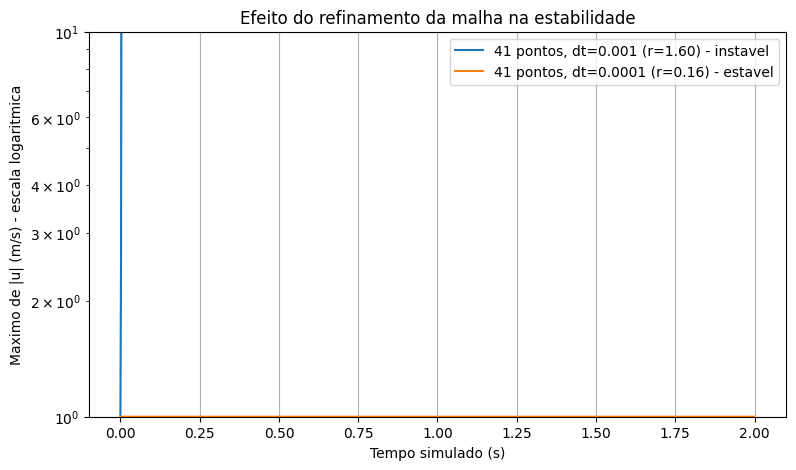

In [ ]:
plt.figure(figsize=(9, 5))
plt.semilogy(res_instavel_41["tempos"], res_instavel_41["maximos"],
             label=f"41 pontos, dt=0.001 (r={res_instavel_41['r']:.2f}) - instavel")
plt.semilogy(res_estavel_41["tempos"], res_estavel_41["maximos"],
             label=f"41 pontos, dt=0.0001 (r={res_estavel_41['r']:.2f}) - estavel")
plt.xlabel("Tempo simulado (s)")
plt.ylabel("Maximo de |u| (m/s) - escala logaritmica")
plt.title("Efeito do refinamento da malha na estabilidade")
plt.grid(True)
plt.legend()
plt.show()

## 6. Verificação do perfil de velocidade

Para observar o regime estacionário, usamos uma execução **estável e suficientemente longa**: malha original de 21 pontos, $\Delta t = 0{,}001$ s (Caso A, $r=0{,}4$), por 6000 passos ($t_{final}=6$ s).

A escala de tempo característica da difusão é $H^2/\nu = (0{,}01)^2 / 10^{-4} = 1$ s, portanto simular por 6 s corresponde a 6 "tempos difusivos" — deve ser suficiente para aproximar bem o regime estacionário.

In [ ]:
U = 1.0
resultado_longo = simular(0.001, np.float64, passos=6000, pontos=21)

y = resultado_longo["y"]
u_final = resultado_longo["u"]
u_est = U * (1 - y / H)

E_inf = np.max(np.abs(u_final - u_est))
print(f"Tempo final simulado: {resultado_longo['tempos'][-1]} s")
print(f"E_inf = max|u_i - u_est(y_i)| = {E_inf:.3e} m/s")

dt=0.001, float64: 6000 passos sem overflow.
Tempo final simulado: 6.0 s
E_inf = max|u_i - u_est(y_i)| = 3.442e-15 m/s


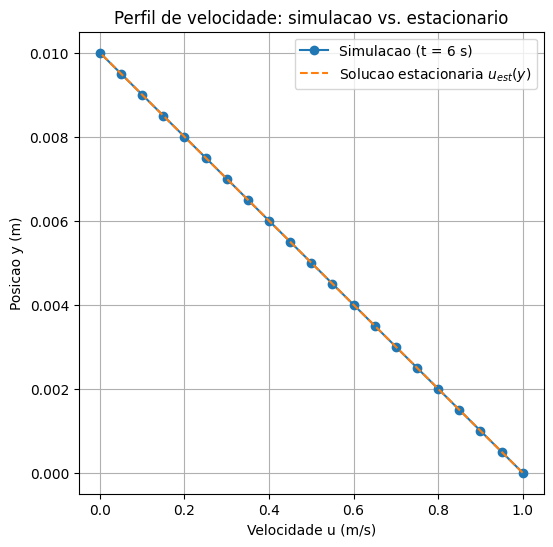

In [ ]:
plt.figure(figsize=(6, 6))
plt.plot(u_final, y, "o-", label="Simulacao (t = 6 s)")
plt.plot(u_est, y, "--", label="Solucao estacionaria $u_{est}(y)$")
plt.xlabel("Velocidade u (m/s)")
plt.ylabel("Posicao y (m)")
plt.title("Perfil de velocidade: simulacao vs. estacionario")
plt.legend()
plt.grid(True)
plt.show()

### O tempo simulado foi suficiente?

Para verificar se o transiente já havia se encerrado, comparamos $E_\infty$ em diferentes instantes de parada:

In [ ]:
print(f"{'passos':>8} | {'tempo (s)':>10} | {'E_inf (m/s)':>14}")
for passos in (200, 1000, 2000, 3000, 6000):
    res = simular(0.001, np.float64, passos=passos, pontos=21)
    u_f = res["u"]
    E = np.max(np.abs(u_f - u_est))
    print(f"{passos:>8} | {res['tempos'][-1]:>10.2f} | {E:>14.3e}")

  passos |  tempo (s) |    E_inf (m/s)
dt=0.001, float64: 200 passos sem overflow.
     200 |       0.20 |      8.775e-02
dt=0.001, float64: 1000 passos sem overflow.
    1000 |       1.00 |      3.194e-05
dt=0.001, float64: 2000 passos sem overflow.
    2000 |       2.00 |      1.605e-09
dt=0.001, float64: 3000 passos sem overflow.
    3000 |       3.00 |      8.082e-14
dt=0.001, float64: 6000 passos sem overflow.
    6000 |       6.00 |      3.442e-15


Os resultados mostram claramente a aproximação ao regime estacionário:

| Tempo simulado | $E_\infty$ (m/s) |
|---|---|
| $t=0{,}2$ s ($0{,}2\,H^2/\nu$) | $\approx 8{,}8\times10^{-2}$ — ainda em transiente |
| $t=1$ s ($1\,H^2/\nu$) | $\approx 3{,}2\times10^{-5}$ |
| $t=2$ s ($2\,H^2/\nu$) | $\approx 1{,}6\times10^{-9}$ |
| $t=3$ s ($3\,H^2/\nu$) | $\approx 8{,}1\times10^{-14}$ |
| $t=6$ s ($6\,H^2/\nu$) | $\approx 3{,}4\times10^{-15}$ (precisão de máquina) |

Ou seja, com apenas $t=0{,}2$ s a solução ainda está longe do perfil estacionário (o transiente domina), mas a partir de aproximadamente **2 a 3 tempos difusivos** ($t \gtrsim 2$–$3$ s) a diferença já é praticamente desprezível. Os 2000 passos usados nos testes das atividades 2 e 4 ($t=2$ s) já correspondem a uma boa aproximação do regime estacionário; o teste de 6000 passos confirma a convergência total.

## 7. Conclusão

Este trabalho evidenciou a relação entre **refinamento da malha**, **passo de tempo**, **instabilidade numérica** e **overflow** no esquema explícito de diferenças finitas para a equação de difusão:

- O esquema é condicionalmente estável, exigindo $r = \dfrac{\nu\Delta t}{\Delta y^2} \le \dfrac{1}{2}$, isto é, $\Delta t \le \dfrac{\Delta y^2}{2\nu}$.
- Quando $r > 1/2$ (Caso B, e também o teste inicial na malha de 41 pontos com $\Delta t=0{,}001$ s), o coeficiente central da atualização se torna negativo, a solução deixa de se comportar como uma média ponderada e passa a **amplificar oscilações exponencialmente**, até que os valores extrapolem a faixa representável pelo tipo numérico, causando o **overflow**.
- **Instabilidade e overflow não são a mesma coisa**: a solução já é fisicamente inválida (velocidades fora de $[0, U]$) muitos passos antes de o programa efetivamente travar por overflow.
- Trocar o tipo numérico de `float32` para `float64` apenas **adia** o instante em que o overflow aparece (por permitir valores muito maiores antes de estourar a faixa representável) — não corrige a causa da instabilidade.
- **Refinar a malha** (aumentar o número de pontos, reduzindo $\Delta y$) **reduz drasticamente o $\Delta t_{max}$** permitido, já que este é proporcional a $\Delta y^2$: dobrar a resolução espacial exige um passo de tempo até 4 vezes menor para preservar a estabilidade.

**A causa da falha observada nesta simulação foi utilizar um $\Delta t$ maior que o limite de estabilidade $\Delta t_{max} = \Delta y^2/(2\nu)$.** A correção que efetivamente resolveu o problema, em ambas as malhas testadas, foi **reduzir o passo de tempo** até satisfazer $r \le 1/2$ (usar $\Delta t = 0{,}001$ s em vez de $0{,}002$ s na malha de 21 pontos, e $\Delta t = 0{,}0001$ s na malha de 41 pontos) — e não a troca do tipo numérico, que apenas mascara o sintoma por mais alguns passos.

## Entrega

Este notebook contém todos os itens solicitados:

- [x] Códigos executados
- [x] Tabela dos testes (Atividade 2)
- [x] Gráfico da velocidade (crescimento e overflow)
- [x] Comparação com o perfil estacionário (Atividade 6)
- [x] Respostas às atividades propostas e conclusão

---
**Dupla:** Nicolas Elias dos Santos (RA: 178196) e Gabriel Andreatta Padilha (RA: 176297)